In [1]:
from app.services.entities import Passenger, Interval, Flight, ArrivalSampler
import app.services.predictive as predictive
import app.services.preprocessing as preprocessing
import app.services.samplers as samplers
import app.services.arrival_flow as arrival_flow
import app.services.security_class as security_class
import app.services.utils as utils
import app.services.plotting_utils as plotutils

import joblib
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast
import json
import requests
import asyncio
from io import BytesIO, StringIO
base_seed = 42

import logging
logging.basicConfig(level=logging.INFO, 
                    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
                    force=True)

#### Testing loop with inherited demand

In [2]:
from app.services.security_class import arrivals_to_demand_grid
from app.services.coverage_dp import solve_coverage_batch_multi, allocate_milp, solve_allocated_multi, effective_grid, coverage_report_multi, fixed_window_solution, MultiAllocation   # MultiAllocation: lo stesso import già usato per allocate_milp

2026-11-26 10:31:58,975 | WARNING | app.services.preprocessing | More than 10% of flights (9/65) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-26 10:32:00,890 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 6 workers


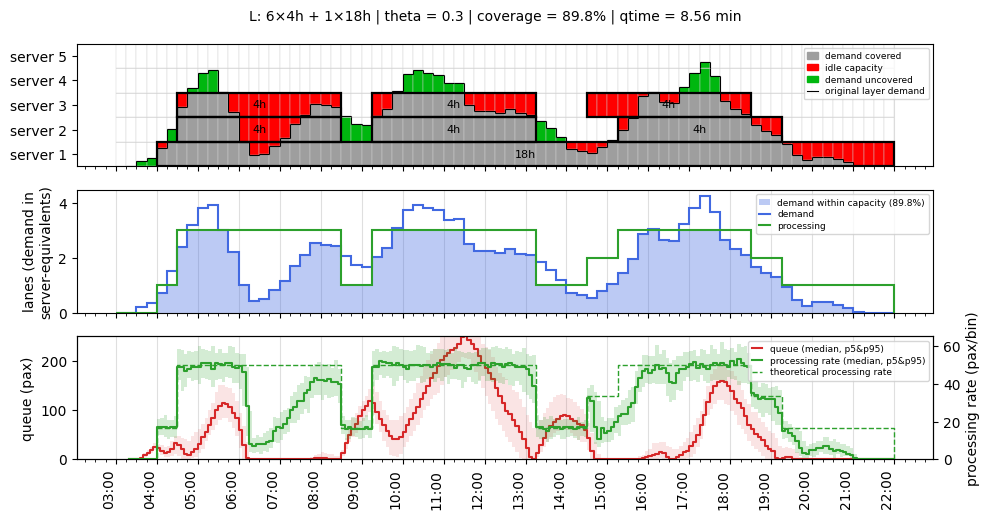

2026-11-26 10:32:26,974 | INFO | app.services.security_class | [SecuritySimulator] 50 total tasks, 6 workers


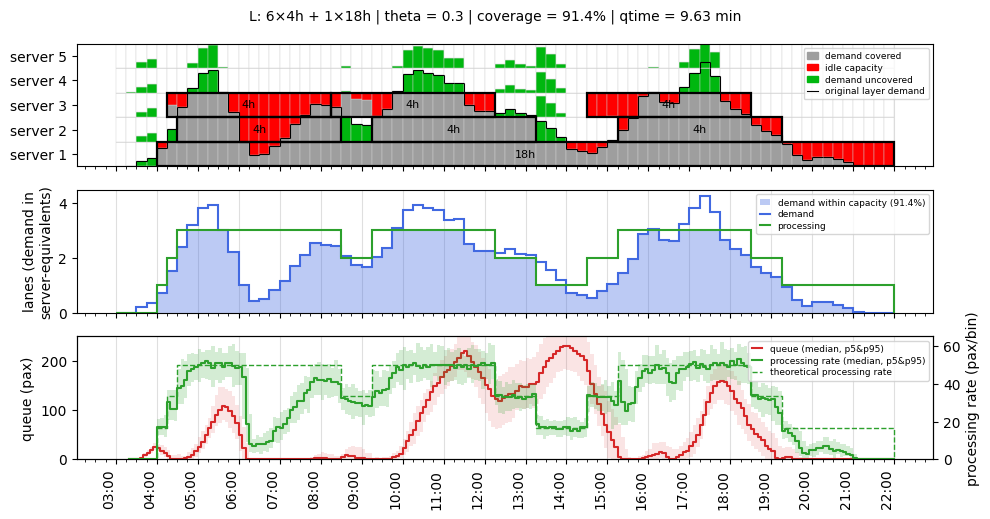

In [21]:
date=dt.datetime(2026, 5, 24)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()

schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)
server_labels = utils.sort_labels_by_priority(server_registry)
rate_by_label, _ = utils.get_processing_rate_by_label(server_registry, 15)
rates_in_order = [rate_by_label[l] for l in server_labels]

arrivals= samplers.expected_arrivals(flight_demand)

lengths=[16]
theta=0.3
K_total= 1000
length_totals={}

bin_min = 15
step = pd.Timedelta(minutes=bin_min)
day = pd.Timestamp(date) 

first = min(arrivals.index[0], day + pd.Timedelta(hours=3))
last  = max(arrivals.index[-1], day + pd.Timedelta(hours=22) - step)
arrivals = arrivals.reindex(pd.date_range(first, last, freq=f"{bin_min}min"), fill_value=0.0)

grid = arrivals_to_demand_grid(arrivals, utils.mean_processing_rate(server_registry))
time_values = pd.DatetimeIndex(arrivals.index)
T = grid.shape[1]
g0 = time_values[0]

start_slot = int((day + pd.Timedelta(hours=4)  - g0) / step)    # 3
end_slot   = int((day + pd.Timedelta(hours=22) - g0) / step)    # 75 = T
assert 0 <= start_slot < end_slot <= T
bounds = (start_slot, end_slot)

fixed = {0: fixed_window_solution(grid[0], theta, start_slot, end_slot - start_slot)}
n_fixed = len(fixed)

curves     = solve_coverage_batch_multi(grid[n_fixed:], lengths, theta, bounds=bounds)
alloc_free = allocate_milp(curves, lengths, K_total=K_total, length_per_day=length_totals)
alloc = MultiAllocation(
    k=np.vstack([np.zeros((n_fixed, len(lengths)), dtype=int), alloc_free.k]),
    lengths=alloc_free.lengths, value=alloc_free.value,
    per_row_value=np.concatenate([np.zeros(n_fixed), alloc_free.per_row_value]))

# senza domanda ereditata-----
sols = solve_allocated_multi(grid, theta, alloc, inherit=False, fixed=fixed, bounds=bounds)

D_eff = effective_grid(grid, [s.coverage for s in sols])

report = coverage_report_multi(grid, sols, time_values=time_values, theta=theta, D_cov=D_eff)

labels = list(server_labels) 
blocks1= {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)] for r, sol in enumerate(sols)}

rho  = grid.sum(axis=0)
proc_plain = np.sum([s.coverage[:grid.shape[1]] for s in sols], axis=0).astype(float)

t0   = pd.Timestamp(time_values[0])
step = pd.Timedelta(minutes=bin_min)

server_schedule = {
    label: [((t0 + int(s)*step).to_pydatetime(),
             (t0 + (int(s)+int(l))*step).to_pydatetime())
            for s, l in bl]
    for label, bl in blocks1.items() if len(bl)
}

sim = security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(server_schedule),
    server_registry=server_registry)
sim_results1 = sim.run(n_scenarios=50, n_workers=6, timebin=5, base_seed=base_seed)
pax1= sim_results1.df_pax
cdf1= sim_results1.df_queue_cdf
max_queue= int(max(sim_results1.df_timeline.queue_length_mean))
plotutils.plot_blocks(D=grid, D_ref=grid, blocks=blocks1, labels=labels, time_values=time_values,
                    theta=theta, bin_minutes=15, demand_curve=rho, processing_curve=proc_plain,
                    df_timeline=sim_results1.df_timeline, df_kpis=sim_results1.df_kpis, queue_max=max_queue)

# con domanda ereditata-----
sols = solve_allocated_multi(grid, theta, alloc, inherit=True, fixed=fixed, bounds=bounds)

D_eff = effective_grid(grid, [s.coverage for s in sols])

report = coverage_report_multi(grid, sols, time_values=time_values, theta=theta, D_cov=D_eff)

labels = list(server_labels) 
blocks2 = {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)] for r, sol in enumerate(sols)}

rho  = grid.sum(axis=0)
proc_inh = np.sum([s.coverage[:grid.shape[1]] for s in sols], axis=0).astype(float)

# sim
t0   = pd.Timestamp(time_values[0])
step = pd.Timedelta(minutes=bin_min)

server_schedule = {
    label: [((t0 + int(s)*step).to_pydatetime(),
             (t0 + (int(s)+int(l))*step).to_pydatetime())
            for s, l in bl]
    for label, bl in blocks2.items() if len(bl)
}

if blocks2 == blocks1:
    logging.warning("Server schedule is the same as the previous one. Skipping simulation.")
else:
    sim = security_class.SecuritySimulator(
        flight_demand=flight_demand,
        intervals=utils.server_schedule_to_intervals(server_schedule),
        server_registry=server_registry)
    sim_results2 = sim.run(n_scenarios=50, n_workers=6, timebin=5, base_seed=base_seed)
    pax2= sim_results2.df_pax
    cdf2= sim_results2.df_queue_cdf

    plotutils.plot_blocks(D=D_eff, D_ref=grid, blocks=blocks2, labels=labels, time_values=time_values,
                        theta=theta, bin_minutes=15, demand_curve=rho, processing_curve=proc_inh,
                        df_timeline=sim_results2.df_timeline, df_kpis=sim_results2.df_kpis, queue_max=max_queue)

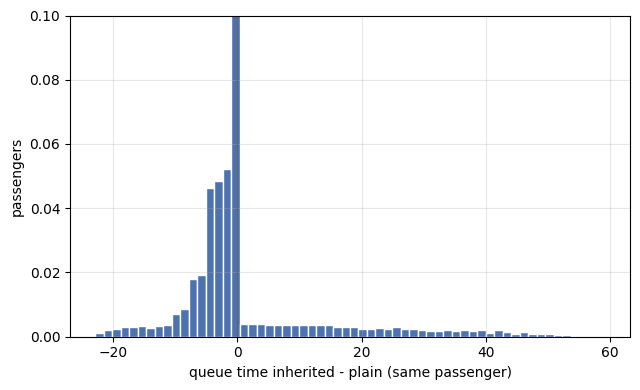

In [23]:
merge_pax = pd.merge(pax1, pax2, on=['scenario_id', 'id'], suffixes=('_plain', '_inherited'), how='outer', indicator=True)
merge_pax['queue_time_diff'] = merge_pax['queue_time_inherited'] - merge_pax['queue_time_plain']
d = merge_pax.loc[merge_pax["_merge"] == "both", "queue_time_diff"].dropna()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(d, bins=60, density=True, color="#4c72b0", edgecolor="white")
ax.axvline(0, color="#666", lw=0.8)
# ax.set_yscale("log")
ax.set_xlabel("queue time inherited - plain (same passenger)"); ax.set_ylabel("passengers")
plt.ylim(0, 0.1)
plt.grid(alpha=0.3)
fig.tight_layout(); plt.show()

          plain  inherited
mean      8.641      9.720
p50       6.854      5.399
p90      20.673     21.913
p95      23.826     35.093
p99      28.558     59.480
P(W>10)   0.384      0.374
P(W>15)   0.221      0.240


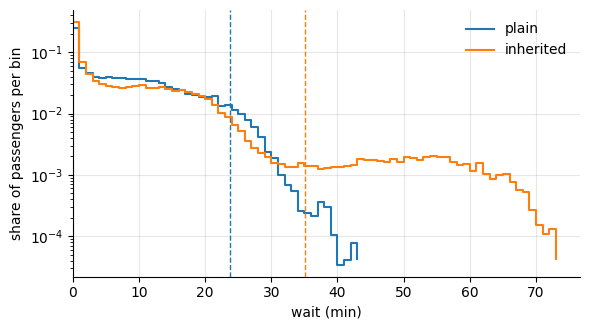

In [24]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

def _cdf(c):
    e = np.r_[c["queue_time_bin_start"].iloc[0], c["queue_time_bin_end"].values].astype(float)
    n = c["cum_count"].values.astype(float)
    return e, np.r_[0.0, n / n[-1]]

def cdf_table(cdfs, labels, qs=(0.5, 0.9, 0.95, 0.99), thr=(10, 15)):
    rows = {}
    for c, lab in zip(cdfs, labels):
        e, p = _cdf(c)
        r = {"mean": (np.diff(p) * (e[:-1] + e[1:]) / 2).sum()}
        r.update({f"p{int(q*100)}": np.interp(q, p, e) for q in qs})
        r.update({f"P(W>{x})": 1 - np.interp(x, e, p) for x in thr})
        rows[lab] = r
    return pd.DataFrame(rows).round(3)

def plot_pdfs(cdfs, labels, xmax=None, q=0.95):
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for k, (c, lab) in enumerate(zip(cdfs, labels)):
        e, p = _cdf(c)
        line, = ax.step(e[:-1], np.clip(np.diff(p), 1e-6, None), where="post", label=lab)
        ax.axvline(np.interp(q, p, e), color=line.get_color(), ls="--", lw=1)
    ax.set_yscale("log"); ax.set_xlim(0, xmax)
    ax.set_xlabel("wait (min)"); ax.set_ylabel("share of passengers per bin")
    ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3); ax.set_axisbelow(True); fig.tight_layout(); plt.show()

print(cdf_table([cdf1, cdf2], ["plain", "inherited"]))

plot_pdfs([cdf1, cdf2], ["plain", "inherited"])

In [ ]:
# ciclo sule date per vedere se cambia qualcosa con inherit

import json, os, pickle
import numpy as np, pandas as pd
from app.services.fluid_approx import capacity_per_slot, fluid_wait

def prepare_day(date, schedule_std, arrival_model, server_registry, pax_model="data/pax_model.joblib",
                bin_min=15, open_h=4, close_h=22):
    day = pd.Timestamp(date).normalize()
    step = pd.Timedelta(minutes=bin_min)
    sched = schedule_std[schedule_std["date"] == date].copy()
    pred = predictive.predict_pax(df=sched, path=pax_model)
    fd = preprocessing.build_flight_demand(pred, arrival_model=arrival_model)
    arr = samplers.expected_arrivals(fd)
    first = min(arr.index[0], day + pd.Timedelta(hours=open_h))
    last  = max(arr.index[-1], day + pd.Timedelta(hours=close_h) - step)
    arr = arr.reindex(pd.date_range(first, last, freq=f"{bin_min}min"), fill_value=0.0)
    grid = arrivals_to_demand_grid(arr, utils.mean_processing_rate(server_registry))
    tv = pd.DatetimeIndex(arr.index)
    s0 = int((day + pd.Timedelta(hours=open_h)  - tv[0]) / step)
    e0 = int((day + pd.Timedelta(hours=close_h) - tv[0]) / step)
    assert 0 <= s0 < e0 <= grid.shape[1]
    return dict(day=day, grid=grid, arr=arr.to_numpy(float), time_values=tv, bounds=(s0, e0), flight_demand=fd)

# ---------- statistiche di attesa da una df_queue_cdf
def _cdf(c):
    e = np.r_[c["queue_time_bin_start"].iloc[0], c["queue_time_bin_end"].values].astype(float)
    n = c["cum_count"].values.astype(float)
    return e, np.r_[0.0, n / n[-1]]

def cdf_stats(c, qs=(0.5, 0.9, 0.95, 0.99), thr=(10, 15)):
    e, p = _cdf(c)
    r = {"mean": float((np.diff(p) * (e[:-1] + e[1:]) / 2).sum())}
    r.update({f"p{int(q*100)}": float(np.interp(q, p, e)) for q in qs})
    r.update({f"P(W>{x})": float(1 - np.interp(x, e, p)) for x in thr})
    return r

def sim_stats(dd, blocks, server_registry, bin_min, n_scenarios, base_seed, n_workers):
    t0, step = pd.Timestamp(dd["time_values"][0]), pd.Timedelta(minutes=bin_min)
    sched = {lab: [((t0 + int(s) * step).to_pydatetime(), (t0 + (int(s) + int(l)) * step).to_pydatetime())
                   for s, l in bl] for lab, bl in blocks.items() if len(bl)}
    sim = security_class.SecuritySimulator(flight_demand=dd["flight_demand"],
                                           intervals=utils.server_schedule_to_intervals(sched),
                                           server_registry=server_registry)
    res = sim.run(n_scenarios=n_scenarios, n_workers=n_workers, timebin=5, base_seed=base_seed)
    return cdf_stats(res.df_queue_cdf)

# ---------- un giorno: (L, theta, inherit)
def compare_inherit(dd, rate_by_label, server_registry, bin_min, thetas, Ls, lane_bins=200,
                    n_scenarios=50, base_seed=0, n_workers=6, q_max=60):
    grid, arr, bounds = dd["grid"], dd["arr"], dd["bounds"]
    s0, e0 = bounds; T = grid.shape[1]
    labels = [str(r + 1) for r in range(grid.shape[0])]
    rows = []
    for L in Ls:
        K = int(lane_bins // L)
        for theta in thetas:
            fixed = {0: fixed_window_solution(grid[0], theta, s0, e0 - s0)}
            curves = solve_coverage_batch_multi(grid[1:], [L], theta, bounds=bounds)
            af = allocate_milp(curves, [L], K_total=K, length_per_day={L: K})
            alloc = MultiAllocation(k=np.vstack([np.zeros((1, 1), dtype=int), af.k]), lengths=af.lengths,
                                    value=af.value, per_row_value=np.concatenate([np.zeros(1), af.per_row_value]))
            caps, bl_by = {}, {}
            for inh in (False, True):
                sols = solve_allocated_multi(grid, theta, alloc, inherit=inh, fixed=fixed, bounds=bounds)
                bl = {labels[r]: [(int(s), int(l)) for s, l in zip(sol.starts, sol.lengths)] for r, sol in enumerate(sols)}
                caps[inh], bl_by[inh] = capacity_per_slot(bl, rate_by_label, T), bl
            changed = not np.allclose(caps[False], caps[True])
            q_plain = fluid_wait(arr, caps[False], bin_min)
            # simulazione: plain sempre (se passa il filtro); inherited solo se il profilo cambia
            stats = {}
            if q_plain < q_max:
                stats[False] = sim_stats(dd, bl_by[False], server_registry, bin_min, n_scenarios, base_seed, n_workers)
                stats[True] = (sim_stats(dd, bl_by[True], server_registry, bin_min, n_scenarios, base_seed, n_workers)
                               if changed else stats[False])

            for inh in (False, True):
                row = dict(day=dd["day"], L=L, K=K, theta=theta, inherit=inh, changed=changed,
                           lane_bins=int(sum(l for b in bl_by[inh].values() for _, l in b)),
                           q_fluid=fluid_wait(arr, caps[inh], bin_min))
                row.update(stats.get(inh, {}))
                rows.append(row)
    return pd.DataFrame(rows)

def compare_inherit_days(dates, schedule_std, arrival_model, server_registry, rate_by_label, thetas, Ls,
                         lane_bins=200, bin_min=15, n_scenarios=50, base_seed=0, n_workers=6, q_max=60,
                         out_path="data/inherit_days_sim.pkl"):
    df_all = pd.read_pickle(out_path) if os.path.exists(out_path) else pd.DataFrame()
    done = set(pd.to_datetime(df_all["day"]).unique()) if len(df_all) else set()
    for i, d in enumerate(dates):
        if pd.Timestamp(d) in done: continue
        try:
            dd = prepare_day(d, schedule_std, arrival_model, server_registry, bin_min=bin_min)
            df_all = pd.concat([df_all, compare_inherit(dd, rate_by_label, server_registry, bin_min, thetas, Ls,
                                lane_bins, n_scenarios, base_seed, n_workers, q_max)], ignore_index=True)
            os.makedirs(os.path.dirname(out_path), exist_ok=True); df_all.to_pickle(out_path)
            print(f"[{i+1}/{len(dates)}] {pd.Timestamp(d).date()} ok")
        except Exception as e:
            print(f"[{i+1}/{len(dates)}] {pd.Timestamp(d).date()} SKIP: {type(e).__name__}: {e}")
    return df_all

# ---------- riassunto: differenze (ereditata - piana), in minuti o in quota di passeggeri
TOL = {"mean": 0.1, "p90": 0.5, "p95": 0.5, "p99": 1.0, "P(W>10)": 0.005, "P(W>15)": 0.005}

def summarize_days(df, metrics=("p95", "p99", "P(W>15)"), by=("theta",), tol=TOL, q_max=30,
                   n_boot=2000, seed=0):
    key = ["day", "L", "theta"]
    p, i = df[~df.inherit].set_index(key), df[df.inherit].set_index(key)
    d = pd.DataFrame({"changed": i["changed"], "q_plain": p["q_fluid"]})
    for m in metrics:
        d["d_" + m] = (i[m] - p[m]).where(d["changed"], 0.0)       # profilo identico -> delta = 0
    d = d[d["q_plain"] < q_max].reset_index()                       # solo i casi che il decisore considererebbe
    rng, out = np.random.default_rng(seed), []
    for k, g in d.groupby(list(by)):
        k = k if isinstance(k, tuple) else (k,)
        groups = [gg for _, gg in g.groupby("day")]                 # bootstrap sui giorni
        nd = len(groups)
        for m in metrics:
            blocks = [b["d_" + m].dropna().to_numpy() for b in groups]
            sums = np.array([b.sum() for b in blocks]); cnts = np.array([len(b) for b in blocks])
            x = np.concatenate(blocks)
            if len(x) == 0: continue
            idx = rng.integers(0, nd, size=(n_boot, nd))
            boots = sums[idx].sum(axis=1) / cnts[idx].sum(axis=1)
            out.append(dict(zip(by, k), metric=m, n=len(x), days=nd, changed=g["changed"].mean(),
                            mean=x.mean(), ci_lo=np.percentile(boots, 2.5), ci_hi=np.percentile(boots, 97.5),
                            median=np.median(x), better=(x < -tol[m]).mean(), worse=(x > tol[m]).mean()))
    return pd.DataFrame(out).round(3)

In [58]:
dates = sorted(schedule_std["date"].unique())[:93]
df_sim = compare_inherit_days(dates, schedule_std, arrival_model, server_registry, rate_by_label,
                              thetas=[round(t, 1) for t in np.arange(0.0, 0.8, 0.1)], Ls=[8, 12, 16],
                              lane_bins=1000, n_scenarios=20, base_seed=base_seed, q_max=60,
                              out_path="data/inherit_full_60.pkl")

2026-11-26 15:08:26,028 | WARNING | app.services.preprocessing | More than 10% of flights (9/63) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-26 15:08:26,406 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:08:30,887 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:08:35,672 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:08:40,730 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:08:45,162 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:08:50,000 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:08:54,677 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:08:59,544 | INFO | app.services.security_class | [

[1/93] 2026-03-29 ok


2026-11-26 15:09:58,940 | WARNING | app.services.preprocessing | More than 10% of flights (13/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-11-26 15:09:59,352 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:10:04,732 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:10:09,271 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:10:14,555 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:10:19,054 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:10:24,605 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:10:30,024 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:10:34,805 | INFO | app.services.security_class | 

[2/93] 2026-03-30 ok


2026-11-26 15:12:09,317 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:13,339 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:18,079 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:22,186 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:26,404 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:30,911 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:35,248 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:39,509 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:43,777 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 15:12:48

[3/93] 2026-03-31 ok


... (174 outputs left out)

2026-11-26 17:49:12,200 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:49:17,410 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:49:22,326 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:49:27,518 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:49:32,426 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:49:37,641 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:49:42,709 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:49:51,408 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:50:00,318 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:50:05

[92/93] 2026-06-28 ok


2026-11-26 17:50:49,681 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:50:54,471 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:50:59,513 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:51:04,769 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:51:10,273 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:51:17,727 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:51:25,328 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:51:30,034 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:51:35,028 | INFO | app.services.security_class | [SecuritySimulator] 20 total tasks, 6 workers
2026-11-26 17:51:39

[93/93] 2026-06-29 ok


In [60]:
df_sim = pd.read_pickle(os.path.join('data', 'inherit_full_60.pkl'))

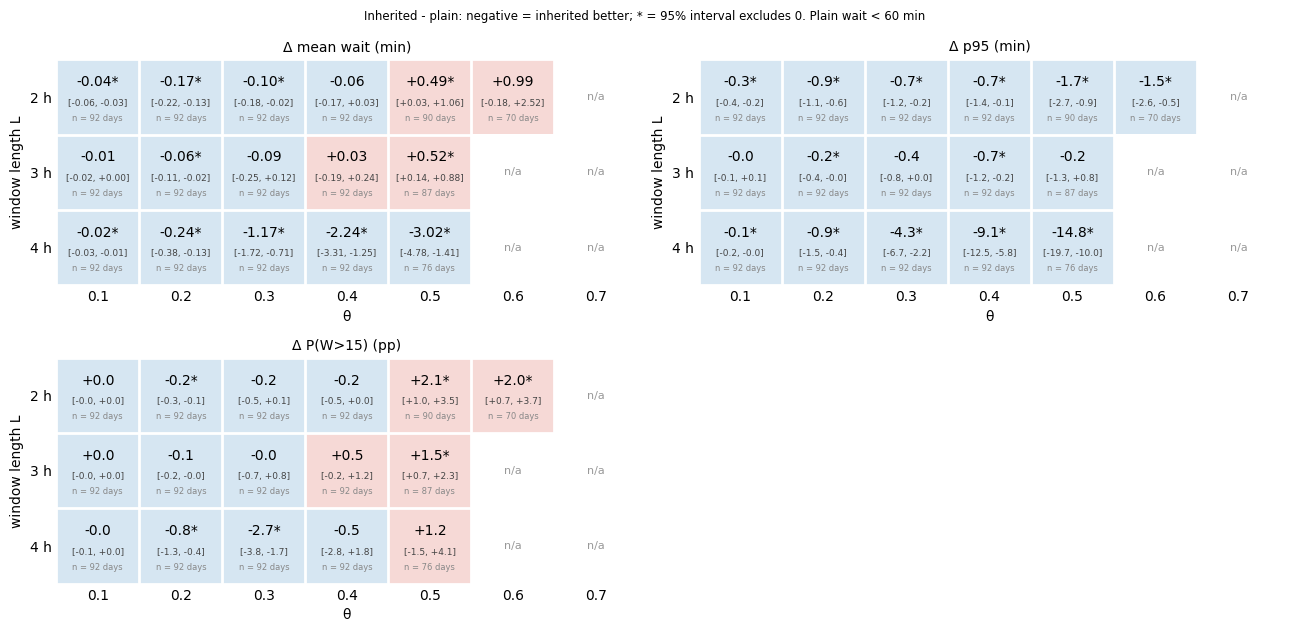

In [67]:
from matplotlib.colors import ListedColormap

def heat_L_theta(df, q_max=15, min_days=15, need_sig=False,
                 metrics=(("p95", "Δ p95 (min)", 1, 1), ("P(W>15)", "Δ P(W>15) (pp)", 100, 1))):
    """Colore = segno della differenza (blu chiaro < 0, rosa chiaro > 0). need_sig=True: colora solo se l'intervallo esclude 0."""
    s = summarize_days(df, by=("L", "theta"), q_max=q_max, metrics=tuple(m[0] for m in metrics))
    Ls, ths = sorted(s["L"].unique()), sorted(s["theta"].unique())
    #remove thtea=0
    ths = [t for t in ths if t != 0]
    cmap = ListedColormap(["#d6e6f2", "#f6d9d6"])                 # negativo, positivo
    
    n = len(metrics); ncols = 2; nrows = int(np.ceil(n / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(6.5 * ncols, 3.2 * nrows), squeeze=False)
    axs = axs.ravel()
    for ax in axs[n:]:
        ax.set_visible(False) 

    for ax, (m, title, k, d) in zip(axs, metrics):
        g = s[s.metric == m].set_index(["L", "theta"])
        sign = np.full((len(Ls), len(ths)), np.nan); cells = {}
        for a, L in enumerate(Ls):
            for b, t in enumerate(ths):
                if (L, t) not in g.index or g.loc[(L, t), "days"] < min_days:
                    cells[(a, b)] = None; continue
                r = g.loc[(L, t)]; sig = r.ci_lo > 0 or r.ci_hi < 0
                if sig or not need_sig: sign[a, b] = 1.0 if r["mean"] > 0 else 0.0
                cells[(a, b)] = (f"{r['mean']*k:+.{d}f}{'*' if sig else ''}",
                 f"[{r.ci_lo*k:+.{d}f}, {r.ci_hi*k:+.{d}f}]",
                 f"n = {int(r['days'])} days")

                
        ax.imshow(np.ma.masked_invalid(sign), cmap=cmap, vmin=0, vmax=1, aspect="auto")
        for (a, b), c in cells.items():
            if c is None:
                ax.text(b, a, "n/a", ha="center", va="center", fontsize=8, color="#999")
            else:
                ax.text(b, a - 0.2, c[0], ha="center", va="center", fontsize=10)
                ax.text(b, a + 0.08, c[1], ha="center", va="center", fontsize=6.5, color="#444")
                ax.text(b, a + 0.28, c[2], ha="center", va="center", fontsize=6, color="#888")
        ax.set_xticks(range(len(ths))); ax.set_xticklabels([f"{t:g}" for t in ths]); ax.set_xlabel("θ")
        ax.set_yticks(range(len(Ls))); ax.set_yticklabels([f"{L*15/60:g} h" for L in Ls]); ax.set_ylabel("window length L")
        ax.set_title(title, fontsize=10)
        for sp in ax.spines.values(): sp.set_visible(False)
        ax.set_xticks(np.arange(-.5, len(ths)), minor=True); ax.set_yticks(np.arange(-.5, len(Ls)), minor=True)
        ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="both", length=0)
    fig.suptitle(f"Inherited - plain: negative = inherited better; * = 95% interval excludes 0. "
                 f"Plain wait < {q_max} min", fontsize=8.5)
    fig.tight_layout(); plt.show()

heat_L_theta(df_sim, q_max=60, min_days=30,
             metrics=(("mean", "Δ mean wait (min)", 1, 2),
                      ("p95", "Δ p95 (min)", 1, 1),
                      ("P(W>15)", "Δ P(W>15) (pp)", 100, 1)))

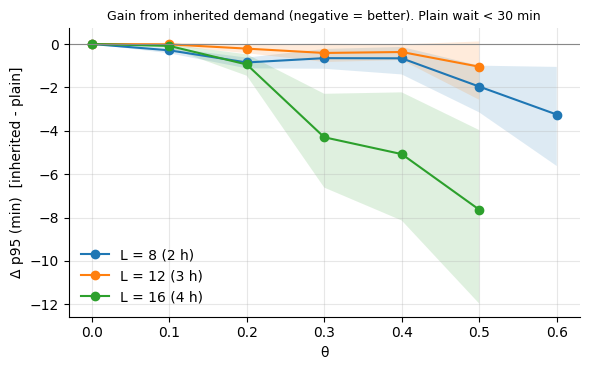

In [62]:
def plot_gain_vs_theta(df, metric="p95", q_max=30, min_days=15, ylabel="Δ p95 (min)  [inherited - plain]", k=1):
    s = summarize_days(df, by=("L", "theta"), q_max=q_max, metrics=(metric,))
    s = s[s["days"] >= min_days]
    fig, ax = plt.subplots(figsize=(6, 3.8))
    for L, g in s.groupby("L"):
        g = g.sort_values("theta")
        ax.plot(g["theta"], g["mean"] * k, marker="o", label=f"L = {L} ({L*15/60:g} h)")
        ax.fill_between(g["theta"], g["ci_lo"] * k, g["ci_hi"] * k, alpha=0.15)
    ax.axhline(0, color="#888", lw=0.8)
    ax.set_xlabel("θ"); ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(s["theta"].unique()))
    ax.set_title(f"Gain from inherited demand (negative = better). Plain wait < {q_max} min", fontsize=9)
    ax.legend(frameon=False); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); plt.show()

plot_gain_vs_theta(df_sim)

#### Testing improve coverage